In [13]:

print("Hello World")
print("start")

Hello World
start


# Exoplanet Hunter

Classify Kepler signals as **confirmed exoplanets** or **false positives** using logistic regression written from scratch with NumPy.

**Data:** NASA Exoplanet Archive, Kepler Objects of Interest (KOI) cumulative table.

**Pipeline:** load and clean, pick features, transform and scale, train/test split, sigmoid + log-loss + gradient ascent, train, evaluate, compare with scikit-learn, save the model for the app.

In [14]:
#setup 
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA_PATH = "../data/kepler_data.csv"   # change this if your file has a different name
SEED = 42
np.random.seed(SEED)

In [15]:
df = pd.read_csv(DATA_PATH, comment="#")
print(df.shape)
df.head()

(9564, 50)


,rowid,kepid,kepoi_name,kepler_name,koi_disposition,koi_pdisposition,koi_score,koi_fpflag_nt,koi_fpflag_ss,koi_fpflag_co,...,koi_steff_err2,koi_slogg,koi_slogg_err1,koi_slogg_err2,koi_srad,koi_srad_err1,koi_srad_err2,ra,dec,koi_kepmag
0,1,10797460,K00752.01,Kepler-227 b,CONFIRMED,CANDIDATE,1.000,0,0,0,...,-81.0,4.467,0.064,-0.096,0.927,0.105,-0.061,291.93423,48.141651,15.347
1,2,10797460,K00752.02,Kepler-227 c,CONFIRMED,CANDIDATE,0.969,0,0,0,...,-81.0,4.467,0.064,-0.096,0.927,0.105,-0.061,291.93423,48.141651,15.347
2,3,10811496,K00753.01,NaN,FALSE POSITIVE,FALSE POSITIVE,0.000,0,1,0,...,-176.0,4.544,0.044,-0.176,0.868,0.233,-0.078,297.00482,48.134129,15.436
3,4,10848459,K00754.01,NaN,FALSE POSITIVE,FALSE POSITIVE,0.000,0,1,0,...,-174.0,4.564,0.053,-0.168,0.791,0.201,-0.067,285.53461,48.285210,15.597
4,5,10854555,K00755.01,Kepler-664 b,CONFIRMED,CANDIDATE,1.000,0,0,0,...,-211.0,4.438,0.070,-0.210,1.046,0.334,-0.133,288.75488,48.226200,15.509


## 1. Target

The `koi_disposition` column has three values. `CANDIDATE` means NASA has not decided yet, so those rows can't be used to train or test. We keep only `CONFIRMED` (label 1) and `FALSE POSITIVE` (label 0).

In [16]:
print(df["koi_disposition"].value_counts())

df = df[df["koi_disposition"].isin(["CONFIRMED", "FALSE POSITIVE"])].copy()
df["label"] = (df["koi_disposition"] == "CONFIRMED").astype(int)   # 1 = exoplanet, 0 = false positive

koi_disposition
FALSE POSITIVE    5023
CONFIRMED         2293
CANDIDATE         2248
Name: count, dtype: int64


## 2. Features

Only physical measurements are used. The `koi_fpflag_*` columns and `koi_score` are left out on purpose: they come from NASA's own vetting process, so they would hand the model the answer (data leakage).

Period, depth, radius, insolation and SNR have a very long right tail, so they get a `log1p` transform before scaling.

In [17]:
FEATURES = [
    "koi_period",     # orbital period (days)
    "koi_duration",   # transit duration (hours)
    "koi_depth",      # transit depth (ppm)
    "koi_prad",       # planetary radius (Earth radii)
    "koi_teq",        # equilibrium temperature (K)
    "koi_insol",      # insolation flux (Earth flux)
    "koi_model_snr",  # signal-to-noise ratio of the transit
    "koi_steff",      # star effective temperature (K)
    "koi_slogg",      # star surface gravity (log10 cm/s^2)
    "koi_srad",       # star radius (solar radii)
    "koi_impact",     # impact parameter
]
LOG_FEATURES = ["koi_period", "koi_depth", "koi_prad", "koi_insol", "koi_model_snr"]

missing = [c for c in FEATURES if c not in df.columns]
assert not missing, f"These columns are not in your file: {missing}"

data = df[FEATURES + ["label"]].dropna()
print("rows kept after dropping missing values:", len(data))
print(data["label"].value_counts())

rows kept after dropping missing values: 7016
label
0    4724
1    2292
Name: count, dtype: int64


## 3. Split and scale

Shuffle, then 80% train / 20% test. Scaling uses the **train** mean and standard deviation only, so nothing from the test set leaks into training. The saved mean and std are reused by the app.

In [18]:
def transform(raw):
    """Log-transform the skewed columns. raw is a 2D array in FEATURES order."""
    X = raw.astype(float).copy()
    for name in LOG_FEATURES:
        j = FEATURES.index(name)
        X[:, j] = np.log1p(X[:, j])
    return X

X_raw = data[FEATURES].to_numpy()
y = data["label"].to_numpy()

# shuffle, then 80% train / 20% test
idx = np.random.permutation(len(X_raw))
split = int(0.8 * len(idx))
train_idx, test_idx = idx[:split], idx[split:]

X_train_raw, y_train = X_raw[train_idx], y[train_idx]
X_test_raw,  y_test  = X_raw[test_idx],  y[test_idx]

X_train_t = transform(X_train_raw)
X_test_t  = transform(X_test_raw)

# scale with TRAIN statistics only
mean = X_train_t.mean(axis=0)
std = X_train_t.std(axis=0)
std[std == 0] = 1.0

def scale(X_t):
    return (X_t - mean) / std

def add_bias(X):
    return np.hstack([np.ones((X.shape[0], 1)), X])

X_train = add_bias(scale(X_train_t))
X_test = add_bias(scale(X_test_t))
print(X_train.shape, X_test.shape)

(5612, 12) (1404, 12)


## 4. The math

**Sigmoid:** $\sigma(z) = \dfrac{1}{1 + e^{-z}}$, with $z = w^\top x$ and $p = \sigma(z)$

**Log-loss:** $J(w) = -\dfrac{1}{m}\sum_{i=1}^{m}\left[y_i \log p_i + (1-y_i)\log(1-p_i)\right]$

**Gradient ascent** on the average log-likelihood (which is $-J$): $w \leftarrow w + \alpha \cdot \dfrac{1}{m} X^\top (y - p)$

Maximising the log-likelihood and minimising log-loss are the same thing, so the loss curve below should go down.

In [19]:
def sigmoid(z):
    z = np.clip(z, -500, 500)          # avoid overflow in exp
    return 1.0 / (1.0 + np.exp(-z))

def log_loss(y, p, eps=1e-12):
    p = np.clip(p, eps, 1 - eps)       # avoid log(0)
    return -np.mean(y * np.log(p) + (1 - y) * np.log(1 - p))

def gradient_ascent(X, y, lr=0.1, n_iter=2000):
    m, n = X.shape
    w = np.zeros(n)
    losses = []
    for _ in range(n_iter):
        p = sigmoid(X @ w)
        gradient = X.T @ (y - p) / m   # gradient of the average log-likelihood
        w = w + lr * gradient          # step UP the log-likelihood
        losses.append(log_loss(y, p))
    return w, losses


## 5. Train

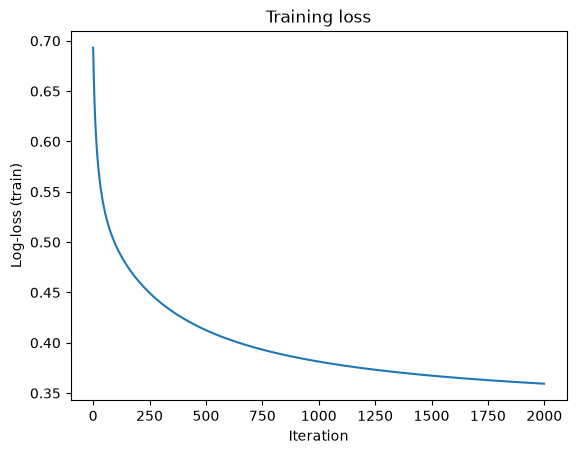

final train loss: 0.3594


In [20]:
w, losses = gradient_ascent(X_train, y_train, lr=0.1, n_iter=2000)

plt.plot(losses)
plt.xlabel("Iteration")
plt.ylabel("Log-loss (train)")
plt.title("Training loss")
plt.show()
print("final train loss:", round(losses[-1], 4))

## 6. Evaluate on the test set

Accuracy alone can mislead when one class is bigger, so precision, recall and F1 are shown too. The majority-class baseline is the accuracy you would get by always predicting the bigger class.

In [21]:
def predict_proba(X, w):
    return sigmoid(X @ w)

def predict(X, w, threshold=0.5):
    return (predict_proba(X, w) >= threshold).astype(int)

def metrics(y_true, y_pred):
    tp = int(np.sum((y_true == 1) & (y_pred == 1)))
    tn = int(np.sum((y_true == 0) & (y_pred == 0)))
    fp = int(np.sum((y_true == 0) & (y_pred == 1)))
    fn = int(np.sum((y_true == 1) & (y_pred == 0)))
    accuracy = (tp + tn) / len(y_true)
    precision = tp / (tp + fp) if (tp + fp) else 0.0
    recall = tp / (tp + fn) if (tp + fn) else 0.0
    f1 = 2 * precision * recall / (precision + recall) if (precision + recall) else 0.0
    return {"accuracy": accuracy, "precision": precision, "recall": recall, "f1": f1,
            "TP": tp, "TN": tn, "FP": fp, "FN": fn}

train_m = metrics(y_train, predict(X_train, w))
test_m = metrics(y_test, predict(X_test, w))

baseline = max(y_test.mean(), 1 - y_test.mean())
print(f"Majority-class baseline accuracy: {baseline:.3f}")
pd.DataFrame({"train": train_m, "test": test_m}).round(3)

Majority-class baseline accuracy: 0.682


,train,test
accuracy,0.839,0.833
precision,0.755,0.743
recall,0.754,0.725
f1,0.754,0.734
TP,1391.000,324.000
TN,3315.000,845.000
FP,452.000,112.000
FN,454.000,123.000


## 7. Sanity check against scikit-learn

scikit-learn's `LogisticRegression` uses L2 regularisation by default, so the numbers should be close but not identical.

In [22]:
from sklearn.linear_model import LogisticRegression

clf = LogisticRegression(max_iter=1000)
clf.fit(X_train[:, 1:], y_train)          # sklearn adds its own bias term
sk_pred = clf.predict(X_test[:, 1:])

print("from-scratch test accuracy:", round(test_m["accuracy"], 3))
print("scikit-learn test accuracy:", round(float(np.mean(sk_pred == y_test)), 3))


from-scratch test accuracy: 0.833
scikit-learn test accuracy: 0.863


## 8. What the model learned

A positive weight pushes a signal towards "confirmed", a negative weight towards "false positive". Features are scaled, so the weights are comparable in size.

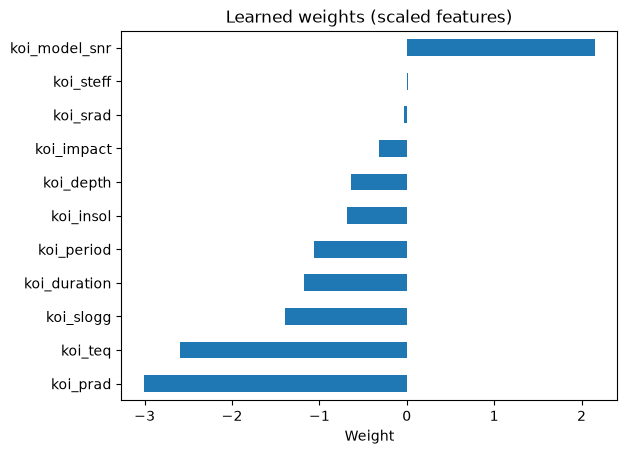

In [23]:
weights = pd.Series(w[1:], index=FEATURES).sort_values()
weights.plot(kind="barh")
plt.title("Learned weights (scaled features)")
plt.xlabel("Weight")
plt.show()

## 9. Save the model

The Streamlit app loads this file, so it needs neither the dataset nor the training code.

In [24]:
os.makedirs("../models", exist_ok=True)
np.savez(
    "../models/weights.npz",
    w=w,
    mean=mean,
    std=std,
    features=np.array(FEATURES),
    log_features=np.array(LOG_FEATURES),
    defaults=np.median(X_train_raw, axis=0),   # typical values, used as defaults in the app
)
print("saved ../models/weights.npz")

saved ../models/weights.npz
